# Notebook 04 — CNN + LSTM baseline (Kaggle GPU)

**Mục tiêu:** huấn luyện baseline CNN–BiLSTM để dự đoán 12 bất thường ở cấp *study* từ DICOM MRI. Notebook chạy trực tiếp trên Kaggle; không tải bộ DICOM 569 GB về máy local.

## Pipeline
1. Đọc `train.csv`, `train_series.csv` và pseudo-label package cuối `pseudo_labels_final_4349.zip` từ `/kaggle/input`.
2. Kiểm tra đúng 4,349 pseudo-labeled studies và 58 gold studies.
3. Chọn tối đa một series cho mỗi mặt phẳng Sagittal / Coronal / Axial, ưu tiên fluid-sensitive series.
4. Đọc header để sắp slice theo vị trí giải phẫu, chọn đều 12 slice mỗi series, chuẩn hóa và cache dưới dạng `uint8` NPY memmap.
5. CNN dùng chung cho từng slice → BiLSTM học chuỗi slice → attention pooling → 12 logits.
6. Train với gold labels có weight 1.0; pseudo-label dùng masked BCE và weight nhỏ hơn. `uncertain` / `not_mentioned` có mask 0.
7. Validation chỉ trên gold studies được giữ lại, tuyệt đối không dùng pseudo-label làm validation ground truth.

## Đầu vào Kaggle cần Add Input
- Competition: **RSNA Knee Abnormality Detection** (có `train.csv`, `train_series.csv`, `train_series/`).
- Kaggle Dataset bạn tạo từ **`pseudo_labels_final_4349.zip`** của Stage C.

## Lưu ý quan trọng
- Chỉ đọc DICOM đã mount sẵn trong `/kaggle/input`; không gọi API tải competition data.
- 58 gold studies rất ít. Validation holdout 12 gold studies vì vậy chỉ là đánh giá sơ bộ; AUC có thể không tính được nếu một target chỉ có một class trong validation.
- Teacher pseudo-label là weak labels, không phải ground truth. Pseudo weight mặc định thấp hơn gold.
- Đây là baseline CNN-LSTM truyền thống, không phải mô hình đã được xác nhận lâm sàng.
- Preprocessed cache khá lớn. Giữ nó trong Kaggle Output và dùng **Save Version** để các notebook ViT/DINOv2 sau này có thể Add Input và tái sử dụng, không cần đọc DICOM lại.

Competition data layout và series metadata theo trang dữ liệu chính thức: `train_series/<StudyInstanceUID>/<SeriesInstanceUID>/<SOPInstanceUID>.dcm`; `train_series.csv` cung cấp anatomical plane, fluid-sensitive và fat-suppression flags.

## 0. Kaggle runtime và dependencies

Chọn Accelerator = GPU trong Kaggle Settings. Cell sau cài decoder DICOM cần thiết. Không tải MRI data.

In [ ]:
# Kaggle-only dependency setup. This installs Python packages, NOT competition data.
%pip install -q "pydicom>=3.0" "pylibjpeg>=2.0" "pylibjpeg-libjpeg>=2.0" "pylibjpeg-openjpeg>=2.0"


In [2]:
import os
import gc
import re
import json
import math
import time
import random
import shutil
import zipfile
import hashlib
import warnings
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, FileLink

import pydicom
from pydicom.pixels import apply_modality_lut
import cv2

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, f1_score, accuracy_score, confusion_matrix

print("Python:", __import__("sys").version.split()[0])
print("PyTorch:", torch.__version__)
print("pydicom:", pydicom.__version__)
print("CUDA available:", torch.cuda.is_available())
if not torch.cuda.is_available():
    raise RuntimeError("Kaggle GPU chưa được bật. Settings → Accelerator → GPU.")
print("GPU count:", torch.cuda.device_count())
for gpu_i in range(torch.cuda.device_count()):
    prop = torch.cuda.get_device_properties(gpu_i)
    print(f"GPU {gpu_i}: {prop.name} | {prop.total_memory / 1024**3:.1f} GiB")


Python: 3.12.13
PyTorch: 2.10.0+cu128
pydicom: 3.0.2
CUDA available: True
GPU count: 2
GPU 0: Tesla T4 | 14.6 GiB
GPU 1: Tesla T4 | 14.6 GiB


## 1. Config + tìm input files

Chỉ tìm pseudo-label files trong `/kaggle/input/datasets`, không quét cây DICOM khổng lồ.

In [3]:
# ----------------------------
# Reproducibility and paths
# ----------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

TARGETS = [
    "ACL", "MCL", "Medial Meniscus", "Lateral Meniscus",
    "Medial OA", "Lateral OA", "PF OA", "Effusion",
    "Synovitis", "Baker's", "Contusion", "Fracture",
]
ID_COL = "StudyInstanceUID"
PLANE_ORDER = ["Sagittal", "Coronal", "Axial"]
PLANE_TO_ID = {"Sagittal": 0, "Coronal": 1, "Axial": 2}

COMP_ROOT = Path("/kaggle/input/competitions/rsna-knee-abnormality-detection")
if not (COMP_ROOT / "train.csv").exists():
    competition_roots = list(Path("/kaggle/input/competitions").glob("*/train.csv"))
    competition_roots = [p.parent for p in competition_roots if (p.parent / "train_series.csv").exists()]
    if not competition_roots:
        raise FileNotFoundError("Không thấy competition input. Add RSNA competition qua Add Input.")
    COMP_ROOT = competition_roots[0]

TRAIN_CSV = COMP_ROOT / "train.csv"
TRAIN_SERIES_CSV = COMP_ROOT / "train_series.csv"
TRAIN_SERIES_DIR = COMP_ROOT / "train_series"

OUTPUT_ROOT = Path("/kaggle/working/rsna_cnn_lstm")
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
CACHE_DIR = OUTPUT_ROOT / "preprocessed_cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# Find final Stage-C package. Kaggle may expose the zip itself or its extracted contents.
DATASETS_ROOT = Path("/kaggle/input/datasets")
REQUIRED_PSEUDO_FILES = {
    "pseudo_labels_numeric.csv",
    "pseudo_labels_mask.csv",
    "pseudo_labels_status.csv",
    "manifest.json",
}

pseudo_dirs = []
pseudo_zip_paths = []
if DATASETS_ROOT.exists():
    for current, dirs, files in os.walk(DATASETS_ROOT):
        file_set = set(files)
        cur = Path(current)
        if REQUIRED_PSEUDO_FILES.issubset(file_set):
            pseudo_dirs.append(cur)
        for filename in files:
            if filename == "pseudo_labels_final_4349.zip":
                pseudo_zip_paths.append(cur / filename)

# Extract a zip only if no already-extracted final package was found.
if not pseudo_dirs and pseudo_zip_paths:
    extract_root = OUTPUT_ROOT / "pseudo_input_extracted"
    extract_root.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(pseudo_zip_paths[0]) as zf:
        zf.extractall(extract_root)
    for current, dirs, files in os.walk(extract_root):
        if REQUIRED_PSEUDO_FILES.issubset(set(files)):
            pseudo_dirs.append(Path(current))

if not pseudo_dirs:
    raise FileNotFoundError(
        "Không tìm thấy final pseudo-label package. Hãy Add Input Kaggle Dataset "
        "được tạo từ pseudo_labels_final_4349.zip (Stage C), không dùng audited ZIP cũ."
    )

# Prefer a package with exactly 4,349 UIDs; reject old 4,208-study package.
PSEUDO_DIR = None
for candidate in pseudo_dirs:
    try:
        candidate_numeric = pd.read_csv(candidate / "pseudo_labels_numeric.csv", usecols=[ID_COL])
        if len(candidate_numeric) == 4349 and candidate_numeric[ID_COL].astype(str).nunique() == 4349:
            PSEUDO_DIR = candidate
            break
    except Exception:
        pass
if PSEUDO_DIR is None:
    found = [(str(p), len(pd.read_csv(p / "pseudo_labels_numeric.csv", usecols=[ID_COL]))) for p in pseudo_dirs]
    raise ValueError(f"Không tìm thấy package có đúng 4,349 UID duy nhất. Candidates: {found}")

print("Competition root:", COMP_ROOT)
print("DICOM root:", TRAIN_SERIES_DIR)
print("Final pseudo-label package:", PSEUDO_DIR)
print("Output root:", OUTPUT_ROOT)


Competition root: /kaggle/input/competitions/rsna-knee-abnormality-detection
DICOM root: /kaggle/input/competitions/rsna-knee-abnormality-detection/train_series
Final pseudo-label package: /kaggle/input/datasets/biinseventeen/pseudo-labels-final-4349-zip
Output root: /kaggle/working/rsna_cnn_lstm


## 2. Load labels, validate 4,349 pseudo + 58 gold, tạo split dùng chung

Các notebook CNN-LSTM, ViT/Transformer và DINOv2 cần dùng đúng cùng `shared_split.csv`. Giữ file này trong output của notebook để tái sử dụng ở hai notebook sau.

In [4]:

# ============================================================
# FIX: LOAD TRAINING LABELS BEFORE BUILDING LABEL MATRICES
# ============================================================

# 1. Load competition metadata
train_df = pd.read_csv(TRAIN_CSV)
series_df = pd.read_csv(TRAIN_SERIES_CSV)

train_df[ID_COL] = train_df[ID_COL].astype(str)
series_df[ID_COL] = series_df[ID_COL].astype(str)

print("Loaded train.csv:", train_df.shape)
print("Loaded train_series.csv:", series_df.shape)

# 2. Identify gold and report-only studies
gold_mask = train_df[TARGETS].notna().all(axis=1)

report_mask = (
    train_df["Report"]
    .fillna("")
    .astype(str)
    .str.strip()
    .ne("")
)

report_only_mask = (
    report_mask
    & train_df[TARGETS].isna().all(axis=1)
)

gold_df = train_df.loc[
    gold_mask, [ID_COL, *TARGETS]
].copy()

expected_pseudo_ids = set(
    train_df.loc[report_only_mask, ID_COL].astype(str)
)

# 3. Load final Stage-C pseudo-label files
pseudo_numeric = pd.read_csv(
    PSEUDO_DIR / "pseudo_labels_numeric.csv"
)

pseudo_mask = pd.read_csv(
    PSEUDO_DIR / "pseudo_labels_mask.csv"
)

pseudo_status = pd.read_csv(
    PSEUDO_DIR / "pseudo_labels_status.csv"
)

for df in [pseudo_numeric, pseudo_mask, pseudo_status]:
    df[ID_COL] = df[ID_COL].astype(str)

# 4. Check columns
for name, df in [
    ("numeric", pseudo_numeric),
    ("mask", pseudo_mask),
    ("status", pseudo_status),
]:
    missing = [
        col for col in [ID_COL, *TARGETS]
        if col not in df.columns
    ]

    if missing:
        raise ValueError(
            f"{name} file missing columns: {missing}"
        )

# 5. Check UID integrity
actual_pseudo_ids = set(
    pseudo_numeric[ID_COL]
)

missing_ids = expected_pseudo_ids - actual_pseudo_ids
extra_ids = actual_pseudo_ids - expected_pseudo_ids

if missing_ids or extra_ids:
    raise ValueError(
        f"Pseudo UID mismatch: "
        f"missing={len(missing_ids)}, "
        f"extra={len(extra_ids)}"
    )

# 6. Validate expected dataset size
assert len(train_df) == 4407, (
    f"Expected 4407 studies, got {len(train_df)}"
)

assert len(gold_df) == 58, (
    f"Expected 58 gold studies, got {len(gold_df)}"
)

assert len(expected_pseudo_ids) == 4349

assert pseudo_numeric[ID_COL].is_unique
assert pseudo_mask[ID_COL].is_unique

print("\n" + "=" * 55)
print("LABEL DATA LOADING SUCCESSFUL")
print("=" * 55)

print("Total training studies:", len(train_df))
print("Gold studies:", len(gold_df))
print("Pseudo-label studies:", len(expected_pseudo_ids))
print("Pseudo numeric shape:", pseudo_numeric.shape)
print("Pseudo mask shape:", pseudo_mask.shape)
print("Pseudo status shape:", pseudo_status.shape)

print("\nAll UID and schema checks passed.")


Loaded train.csv: (4407, 14)
Loaded train_series.csv: (24371, 5)

LABEL DATA LOADING SUCCESSFUL
Total training studies: 4407
Gold studies: 58
Pseudo-label studies: 4349
Pseudo numeric shape: (4349, 13)
Pseudo mask shape: (4349, 13)
Pseudo status shape: (4349, 13)

All UID and schema checks passed.


In [5]:
# Numeric target matrix and mask matrix in train.csv row order.
gold_id_set = set(gold_df[ID_COL].astype(str))
pseudo_numeric = pseudo_numeric.set_index(ID_COL).reindex(train_df[ID_COL])
pseudo_mask = pseudo_mask.set_index(ID_COL).reindex(train_df[ID_COL])

n_studies = len(train_df)
y_matrix = np.zeros((n_studies, len(TARGETS)), dtype=np.float32)
mask_matrix = np.zeros((n_studies, len(TARGETS)), dtype=np.float32)
sample_weights = np.zeros(n_studies, dtype=np.float32)
source_names = np.empty(n_studies, dtype=object)

for row_idx, uid in enumerate(train_df[ID_COL].astype(str)):
    if uid in gold_id_set:
        vals = train_df.iloc[row_idx][TARGETS].to_numpy(dtype=np.float32)
        if not np.isin(vals, [0.0, 1.0]).all():
            raise ValueError(f"Gold labels are not binary for UID {uid}")
        y_matrix[row_idx] = vals
        mask_matrix[row_idx] = 1.0
        sample_weights[row_idx] = 1.0
        source_names[row_idx] = "gold"
    else:
        num = pseudo_numeric.loc[uid, TARGETS].apply(pd.to_numeric, errors="coerce").to_numpy(dtype=np.float32)
        msk = pseudo_mask.loc[uid, TARGETS].apply(pd.to_numeric, errors="coerce").fillna(0).to_numpy(dtype=np.float32)
        if not np.isin(msk, [0, 1]).all():
            raise ValueError(f"Invalid pseudo mask values for UID {uid}")
        if np.any((msk == 1) & (~np.isfinite(num) | ~np.isin(num, [0, 1]))):
            raise ValueError(f"Mask=1 but numeric label is not binary for UID {uid}")
        y_matrix[row_idx] = np.nan_to_num(num, nan=0.0)
        mask_matrix[row_idx] = msk
        sample_weights[row_idx] = 0.05  # weak labels deliberately down-weighted
        source_names[row_idx] = "pseudo"

gold_ids_sorted = sorted(gold_df[ID_COL].astype(str).tolist())
gold_train_ids, gold_val_ids = train_test_split(
    gold_ids_sorted, test_size=0.20, random_state=SEED
)
gold_train_ids, gold_val_ids = set(gold_train_ids), set(gold_val_ids)
pseudo_train_ids = {
    uid for idx, uid in enumerate(train_df[ID_COL].astype(str))
    if source_names[idx] == "pseudo" and mask_matrix[idx].sum() > 0
}

split_rows = []
for uid in train_df[ID_COL].astype(str):
    if uid in gold_val_ids:
        role = "gold_validation"
    elif uid in gold_train_ids:
        role = "gold_train"
    else:
        role = "pseudo_train" if uid in pseudo_train_ids else "pseudo_no_trainable_labels"
    split_rows.append({ID_COL: uid, "split": role})
shared_split = pd.DataFrame(split_rows)
shared_split_path = OUTPUT_ROOT / "shared_split.csv"
shared_split.to_csv(shared_split_path, index=False)

# Persist lightweight label table for future model notebooks.
label_table = pd.DataFrame({ID_COL: train_df[ID_COL].astype(str)})
for j, target in enumerate(TARGETS):
    label_table[target] = np.where(mask_matrix[:, j] > 0, y_matrix[:, j], np.nan)
label_table["label_source"] = source_names
label_table["sample_weight"] = sample_weights
label_table.to_csv(OUTPUT_ROOT / "study_labels_training.csv", index=False)

print("Total studies:", n_studies)
print("Gold studies:", len(gold_ids_sorted))
print("Gold train / validation:", len(gold_train_ids), "/", len(gold_val_ids))
val_gold = train_df.set_index(ID_COL).loc[sorted(gold_val_ids), TARGETS]
print("Validation per-target positive counts:")
display(pd.DataFrame({"target": TARGETS, "positive": val_gold.sum(axis=0).astype(int).values, "negative": (len(val_gold) - val_gold.sum(axis=0)).astype(int).values}))
print("Pseudo studies:", len(expected_pseudo_ids))
print("Pseudo studies with >=1 trainable label:", len(pseudo_train_ids))
print("Trainable pseudo target cells:", int(mask_matrix[source_names == "pseudo"].sum()))
print("Gold target cells:", int(mask_matrix[source_names == "gold"].sum()))
print("Saved shared split:", shared_split_path)
display(pd.DataFrame({
    "target": TARGETS,
    "gold_positive": (y_matrix[source_names == "gold"] * mask_matrix[source_names == "gold"]).sum(axis=0).astype(int),
    "pseudo_positive": (y_matrix[source_names == "pseudo"] * mask_matrix[source_names == "pseudo"]).sum(axis=0).astype(int),
    "pseudo_trainable": mask_matrix[source_names == "pseudo"].sum(axis=0).astype(int),
}))


Total studies: 4407
Gold studies: 58
Gold train / validation: 46 / 12
Validation per-target positive counts:


,target,positive,negative
0,ACL,3,9
1,MCL,3,9
2,Medial Meniscus,5,7
3,Lateral Meniscus,4,8
4,Medial OA,4,8
5,Lateral OA,0,12
6,PF OA,4,8
7,Effusion,8,4
8,Synovitis,4,8
9,Baker's,2,10


Pseudo studies: 4349
Pseudo studies with >=1 trainable label: 4320
Trainable pseudo target cells: 37150
Gold target cells: 696
Saved shared split: /kaggle/working/rsna_cnn_lstm/shared_split.csv


,target,gold_positive,pseudo_positive,pseudo_trainable
0,ACL,24,571,3871
1,MCL,9,439,3762
2,Medial Meniscus,26,1707,3828
3,Lateral Meniscus,23,807,3989
4,Medial OA,15,1318,2729
5,Lateral OA,11,686,2782
6,PF OA,21,867,2656
7,Effusion,35,2038,3969
8,Synovitis,27,614,1836
9,Baker's,12,1084,3782


## 3. Chọn series cho từng study

Baseline này chọn **tối đa một series cho mỗi anatomical plane** (Sagittal, Coronal, Axial). Trong mỗi plane, ưu tiên `Fluid_Sensitive=1`, sau đó ưu tiên `Fat_Suppression=1`. Các series khác vẫn nằm trong DICOM input nhưng không được sử dụng ở baseline này.

Lựa chọn này là một trade-off có chủ đích để có baseline khả thi trên Kaggle. Sau đó có thể mở rộng sang nhiều series/plane trong ablation.

In [6]:
# Normalize series metadata and select up to 3 series per study.
series_df["SeriesInstanceUID"] = series_df["SeriesInstanceUID"].astype(str)
series_df["plane_norm"] = series_df["Anatomical_Plane"].astype(str).str.strip().str.title()
series_df["fluid_num"] = pd.to_numeric(series_df["Fluid_Sensitive"], errors="coerce").fillna(-1)
series_df["fat_num"] = pd.to_numeric(series_df["Fat_Suppression"], errors="coerce").fillna(-1)

selected_rows = []
selected_by_uid = defaultdict(list)
plane_presence = []

for uid, group in series_df.groupby(ID_COL, sort=False):
    present = []
    for plane in PLANE_ORDER:
        candidates = group[group["plane_norm"].eq(plane)].copy()
        if candidates.empty:
            continue
        candidates = candidates.sort_values(
            ["fluid_num", "fat_num", "SeriesInstanceUID"],
            ascending=[False, False, True],
            kind="mergesort",
        )
        chosen = candidates.iloc[0]
        item = {
            ID_COL: str(uid),
            "SeriesInstanceUID": str(chosen["SeriesInstanceUID"]),
            "Anatomical_Plane": plane,
            "plane_id": PLANE_TO_ID[plane],
            "Fluid_Sensitive": int(chosen["fluid_num"]) if chosen["fluid_num"] in (0, 1) else -1,
            "Fat_Suppression": int(chosen["fat_num"]) if chosen["fat_num"] in (0, 1) else -1,
        }
        selected_rows.append(item)
        selected_by_uid[str(uid)].append(item)
        present.append(plane)
    plane_presence.append({ID_COL: str(uid), "n_planes_selected": len(present), "planes": ";".join(present)})

selected_series_df = pd.DataFrame(selected_rows)
plane_presence_df = pd.DataFrame(plane_presence)
selected_series_path = OUTPUT_ROOT / "selected_series_index.csv"
selected_series_df.to_csv(selected_series_path, index=False)

print("Selected series rows:", len(selected_series_df))
print("Studies with 3 planes:", int((plane_presence_df.n_planes_selected == 3).sum()))
print("Studies with 2 planes:", int((plane_presence_df.n_planes_selected == 2).sum()))
print("Studies with 1 plane:", int((plane_presence_df.n_planes_selected == 1).sum()))
print("Studies with 0 planes:", int((plane_presence_df.n_planes_selected == 0).sum()))
display(selected_series_df.head(10))


Selected series rows: 13221
Studies with 3 planes: 4407
Studies with 2 planes: 0
Studies with 1 plane: 0
Studies with 0 planes: 0


,StudyInstanceUID,SeriesInstanceUID,Anatomical_Plane,plane_id,Fluid_Sensitive,Fat_Suppression
0,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.12343110195036213483...,Sagittal,0,1,1
1,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.40734206102458723096...,Coronal,1,1,1
2,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.13821229744997220641...,Axial,2,1,1
3,1.2.826.0.1.3680043.8.498.10004945927472656027...,1.2.826.0.1.3680043.8.498.72137122913943091996...,Sagittal,0,1,1
4,1.2.826.0.1.3680043.8.498.10004945927472656027...,1.2.826.0.1.3680043.8.498.99023014295026495734...,Coronal,1,1,1
5,1.2.826.0.1.3680043.8.498.10004945927472656027...,1.2.826.0.1.3680043.8.498.83327574802189551711...,Axial,2,1,1
6,1.2.826.0.1.3680043.8.498.10009278692606631573...,1.2.826.0.1.3680043.8.498.93288538765996574291...,Sagittal,0,1,1
7,1.2.826.0.1.3680043.8.498.10009278692606631573...,1.2.826.0.1.3680043.8.498.12689544351656485342...,Coronal,1,1,1
8,1.2.826.0.1.3680043.8.498.10009278692606631573...,1.2.826.0.1.3680043.8.498.26515132645256697953...,Axial,2,1,1
9,1.2.826.0.1.3680043.8.498.10009639203170750274...,1.2.826.0.1.3680043.8.498.18313433830014722992...,Sagittal,0,1,1


## 4. DICOM helper functions + slice preprocessing

Slice order dùng `ImagePositionPatient` projected onto slice normal nếu metadata đầy đủ; fallback `InstanceNumber`, cuối cùng filename. Chọn đều 12 slices/series. Normalize theo percentile trong từng series rồi resize 224×224.

In [7]:
IMG_SIZE = 224
SLICES_PER_SERIES = 12
MAX_SERIES_PER_STUDY = 3
MAX_TOTAL_SLICES = SLICES_PER_SERIES * MAX_SERIES_PER_STUDY
MIN_DECODED_SLICES_PER_SERIES = 4


def _safe_float(value, default=np.nan):
    try:
        return float(value)
    except Exception:
        return default


def _slice_sort_key(header_info):
    # The caller sets a numeric sort_value from ImagePositionPatient or InstanceNumber.
    return (header_info["sort_mode"], header_info["sort_value"], header_info["filename"])


def read_sorted_dicom_headers(series_dir: Path):
    paths = sorted([p for p in series_dir.iterdir() if p.is_file() and p.suffix.lower() == ".dcm"])
    if not paths:
        return []

    rows = []
    first_normal = None
    for path in paths:
        try:
            ds = pydicom.dcmread(
                str(path), stop_before_pixels=True, force=True,
                specific_tags=["ImagePositionPatient", "ImageOrientationPatient", "InstanceNumber"]
            )
            iop = getattr(ds, "ImageOrientationPatient", None)
            ipp = getattr(ds, "ImagePositionPatient", None)
            instance = _safe_float(getattr(ds, "InstanceNumber", np.nan))

            position_value = np.nan
            if iop is not None and ipp is not None and len(iop) >= 6 and len(ipp) >= 3:
                row_cos = np.asarray(iop[:3], dtype=np.float64)
                col_cos = np.asarray(iop[3:6], dtype=np.float64)
                normal = np.cross(row_cos, col_cos)
                norm = np.linalg.norm(normal)
                if norm > 0:
                    normal = normal / norm
                    if first_normal is None:
                        first_normal = normal
                    position_value = float(np.dot(np.asarray(ipp[:3], dtype=np.float64), first_normal))

            rows.append({
                "path": path,
                "filename": path.name,
                "position": position_value,
                "instance": instance,
            })
        except Exception as exc:
            rows.append({
                "path": path, "filename": path.name,
                "position": np.nan, "instance": np.nan,
                "header_error": f"{type(exc).__name__}: {exc}",
            })

    valid_pos = sum(np.isfinite(r.get("position", np.nan)) for r in rows)
    valid_inst = sum(np.isfinite(r.get("instance", np.nan)) for r in rows)
    if valid_pos >= max(2, int(0.7 * len(rows))):
        rows.sort(key=lambda r: (np.inf if not np.isfinite(r.get("position", np.nan)) else r["position"], r["filename"]))
        sort_mode = "ImagePositionPatient"
    elif valid_inst >= max(2, int(0.7 * len(rows))):
        rows.sort(key=lambda r: (np.inf if not np.isfinite(r.get("instance", np.nan)) else r["instance"], r["filename"]))
        sort_mode = "InstanceNumber"
    else:
        def natural_key(name):
            return [int(part) if part.isdigit() else part.lower()
                    for part in re.split(r"(\d+)", name)]
        rows.sort(key=lambda r: natural_key(r["filename"]))
        sort_mode = "filename_fallback"

    for i, r in enumerate(rows):
        r["sort_index"] = i
        r["sort_mode"] = sort_mode
    return rows


def decode_dicom_slice(path: Path):
    ds = pydicom.dcmread(str(path), force=True)
    pixels = np.asarray(ds.pixel_array)

    if pixels.ndim == 3:
        # Multi-frame / unexpected color fallback: take the central frame or convert RGB.
        if pixels.shape[-1] in (3, 4):
            pixels = pixels[..., :3].astype(np.float32)
            pixels = 0.299 * pixels[..., 0] + 0.587 * pixels[..., 1] + 0.114 * pixels[..., 2]
        else:
            pixels = pixels[pixels.shape[0] // 2]
    pixels = np.squeeze(pixels)
    if pixels.ndim != 2:
        raise ValueError(f"Expected 2D MRI slice, got shape={pixels.shape}")

    pixels = pixels.astype(np.float32)
    # Apply modality transform if present.
    try:
        pixels = np.asarray(apply_modality_lut(pixels, ds), dtype=np.float32)
    except Exception:
        slope = _safe_float(getattr(ds, "RescaleSlope", 1.0), 1.0)
        intercept = _safe_float(getattr(ds, "RescaleIntercept", 0.0), 0.0)
        pixels = pixels * slope + intercept

    if str(getattr(ds, "PhotometricInterpretation", "MONOCHROME2")).upper() == "MONOCHROME1":
        lo, hi = np.nanmin(pixels), np.nanmax(pixels)
        pixels = hi + lo - pixels

    pixels[~np.isfinite(pixels)] = 0
    return pixels


def normalize_resize_series(image_list, output_size=IMG_SIZE):
    if not image_list:
        return []
    all_values = np.concatenate([img.reshape(-1) for img in image_list])
    lo, hi = np.percentile(all_values, [1.0, 99.5])
    if not np.isfinite(lo) or not np.isfinite(hi) or hi <= lo:
        lo = float(np.min(all_values))
        hi = float(np.max(all_values))
    if hi <= lo:
        hi = lo + 1.0

    output = []
    for img in image_list:
        x = np.clip(img, lo, hi)
        x = (x - lo) / (hi - lo)
        x = np.clip(x, 0, 1)
        x = (x * 255.0).round().astype(np.uint8)
        x = cv2.resize(x, (output_size, output_size), interpolation=cv2.INTER_AREA)
        output.append(x)
    return output


def process_one_series(series_row):
    uid = str(series_row[ID_COL])
    series_uid = str(series_row["SeriesInstanceUID"])
    plane = str(series_row["Anatomical_Plane"])
    series_dir = TRAIN_SERIES_DIR / uid / series_uid
    if not series_dir.exists():
        return [], [], f"missing_series_directory: {series_dir}"

    headers = read_sorted_dicom_headers(series_dir)
    if not headers:
        return [], [], "no_dicom_files"

    n = len(headers)
    target_n = min(SLICES_PER_SERIES, n)
    initial = np.unique(np.linspace(0, n - 1, target_n).round().astype(int)).tolist()
    # Try uniform samples first; add unsampled neighbors only if decoder failures occur.
    candidates = initial + [i for i in range(n) if i not in set(initial)]

    decoded = []
    decoded_positions = []
    errors = []
    for idx in candidates:
        try:
            img = decode_dicom_slice(headers[idx]["path"])
            decoded.append(img)
            decoded_positions.append(idx / max(n - 1, 1))
            if len(decoded) >= SLICES_PER_SERIES:
                break
        except Exception as exc:
            errors.append(f"{headers[idx]['filename']}: {type(exc).__name__}: {exc}")

    if len(decoded) < MIN_DECODED_SLICES_PER_SERIES:
        return [], [], "too_few_decoded_slices: " + " | ".join(errors[:2])

    # Re-sort decoded samples by their original anatomical order; candidates were sampled then fallback.
    order = np.argsort(decoded_positions)
    decoded = [decoded[i] for i in order]
    decoded_positions = [decoded_positions[i] for i in order]
    normalized = normalize_resize_series(decoded)

    plane_id = PLANE_TO_ID.get(plane, -1)
    fluid = int(series_row["Fluid_Sensitive"]) if str(series_row["Fluid_Sensitive"]) in {"0", "1", "0.0", "1.0"} else -1
    fat = int(series_row["Fat_Suppression"]) if str(series_row["Fat_Suppression"]) in {"0", "1", "0.0", "1.0"} else -1

    metadata = [
        {"plane_id": plane_id, "fluid": fluid, "fat": fat, "position": float(pos)}
        for pos in decoded_positions
    ]
    return normalized, metadata, "ok"


def process_one_study(uid):
    image_list = []
    metadata_list = []
    used_series = []
    errors = []

    selected = selected_by_uid.get(str(uid), [])
    # Keep fixed plane order: Sagittal → Coronal → Axial.
    selected = sorted(selected, key=lambda x: x["plane_id"])

    for item in selected:
        row = pd.Series(item)
        try:
            imgs, metas, status = process_one_series(row)
        except Exception as exc:
            imgs, metas = [], []
            status = f"exception:{type(exc).__name__}:{exc}"
        if status == "ok":
            image_list.extend(imgs)
            metadata_list.extend(metas)
            used_series.append(item["SeriesInstanceUID"])
        else:
            errors.append(f"{item['Anatomical_Plane']}:{item['SeriesInstanceUID']}:{status}")

    if not image_list:
        return None, None, {"status": "failed", "error": "; ".join(errors) or "no selected series", "used_series": used_series}

    if len(image_list) > MAX_TOTAL_SLICES:
        image_list = image_list[:MAX_TOTAL_SLICES]
        metadata_list = metadata_list[:MAX_TOTAL_SLICES]

    images = np.zeros((MAX_TOTAL_SLICES, IMG_SIZE, IMG_SIZE), dtype=np.uint8)
    plane_ids = np.full(MAX_TOTAL_SLICES, -1, dtype=np.int8)
    fluid_flags = np.full(MAX_TOTAL_SLICES, -1, dtype=np.int8)
    fat_flags = np.full(MAX_TOTAL_SLICES, -1, dtype=np.int8)
    positions = np.zeros(MAX_TOTAL_SLICES, dtype=np.float32)
    valid = np.zeros(MAX_TOTAL_SLICES, dtype=np.uint8)

    n_valid = len(image_list)
    images[:n_valid] = np.stack(image_list, axis=0)
    valid[:n_valid] = 1
    for i, meta in enumerate(metadata_list):
        plane_ids[i] = meta["plane_id"]
        fluid_flags[i] = meta["fluid"]
        fat_flags[i] = meta["fat"]
        positions[i] = meta["position"]

    return (images, plane_ids, fluid_flags, fat_flags, positions, valid), metadata_list, {
        "status": "ok", "error": "; ".join(errors),
        "n_slices": n_valid, "n_series_used": len(used_series),
        "used_series": ";".join(used_series),
    }


## 5. Smoke test: đọc 5 studies trước khi xử lý toàn bộ

Chạy smoke test trước để kiểm tra đường dẫn, codec DICOM và output tensor. Nếu lỗi JPEG/JPEG2000, cell sẽ hiện thông báo cụ thể; chưa tạo cache full.

Smoke 1/5 UID=1.2.826.0.1.3680043.8.498.10004873229099053869093324292195817260 status=ok slices=36 error=
Smoke 2/5 UID=1.2.826.0.1.3680043.8.498.10004945927472656027199792075652399585 status=ok slices=36 error=
Smoke 3/5 UID=1.2.826.0.1.3680043.8.498.10009278692606631573540062909909132231 status=ok slices=36 error=
Smoke 4/5 UID=1.2.826.0.1.3680043.8.498.10009639203170750274174707434356622764 status=ok slices=36 error=
Smoke 5/5 UID=1.2.826.0.1.3680043.8.498.10013663742400736029415768216599146542 status=ok slices=36 error=


,StudyInstanceUID,status,error,n_slices,n_series_used,used_series
0,1.2.826.0.1.3680043.8.498.10004873229099053869...,ok,,36,3,1.2.826.0.1.3680043.8.498.12343110195036213483...
1,1.2.826.0.1.3680043.8.498.10004945927472656027...,ok,,36,3,1.2.826.0.1.3680043.8.498.72137122913943091996...
2,1.2.826.0.1.3680043.8.498.10009278692606631573...,ok,,36,3,1.2.826.0.1.3680043.8.498.93288538765996574291...
3,1.2.826.0.1.3680043.8.498.10009639203170750274...,ok,,36,3,1.2.826.0.1.3680043.8.498.18313433830014722992...
4,1.2.826.0.1.3680043.8.498.10013663742400736029...,ok,,36,3,1.2.826.0.1.3680043.8.498.70243599053060014636...


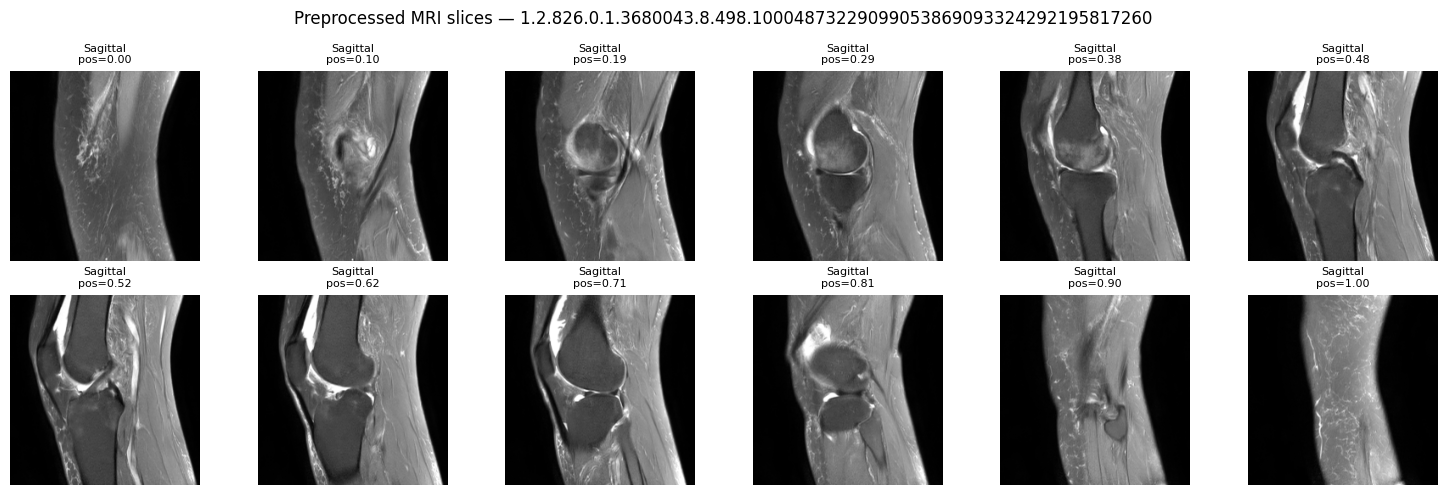

Smoke test passed. Safe to start full preprocessing.


In [8]:
smoke_ids = train_df[ID_COL].astype(str).head(5).tolist()
smoke_results = []
smoke_example = None

for i, uid in enumerate(smoke_ids, start=1):
    result, _, info = process_one_study(uid)
    smoke_results.append({ID_COL: uid, **info})
    print(
        f"Smoke {i}/{len(smoke_ids)} UID={uid} status={info['status']} "
        f"slices={info.get('n_slices', 0)} error={info.get('error', '')[:180]}",
        flush=True,
    )
    if result is not None and smoke_example is None:
        smoke_example = (uid, result)

smoke_df = pd.DataFrame(smoke_results)
display(smoke_df)
if smoke_df["status"].eq("ok").sum() < 4:
    raise RuntimeError(
        "Smoke test failed for too many studies. Check DICOM decoders / dataset paths before full preprocessing."
    )

if smoke_example is not None:
    uid, result = smoke_example
    imgs, plane_ids, fluid, fat, positions, valid = result
    valid_ix = np.where(valid > 0)[0][:12]
    fig, axes = plt.subplots(2, 6, figsize=(15, 5))
    for ax, ix in zip(axes.flat, valid_ix):
        ax.imshow(imgs[ix], cmap="gray")
        plane_name = PLANE_ORDER[int(plane_ids[ix])] if plane_ids[ix] >= 0 else "unknown"
        ax.set_title(f"{plane_name}\npos={positions[ix]:.2f}", fontsize=8)
        ax.axis("off")
    for ax in axes.flat[len(valid_ix):]:
        ax.axis("off")
    plt.suptitle(f"Preprocessed MRI slices — {uid}")
    plt.tight_layout()
    plt.show()

print("Smoke test passed. Safe to start full preprocessing.")


## 6. Full DICOM preprocessing + resumable cache

Cache gồm:
- `train_slices_uint8.npy`: `(4407, 36, 224, 224)`, `uint8` (~7.4 GiB nếu full).
- `slice_valid.npy`, `plane_ids.npy`, `fluid_flags.npy`, `fat_flags.npy`, `slice_positions.npy`.
- `preprocess_status.csv`: UID, status, số slice, lỗi; cell có thể resume và bỏ qua UID đã `ok`.

Kaggle `/kaggle/working` có giới hạn dung lượng. Kiểm tra dung lượng trống ở đầu cell. Nếu không đủ ~9 GiB, giảm `IMG_SIZE` trong cell helper xuống 160 (cần chạy lại smoke test và cache từ đầu).

In [9]:
# Full cache configuration.
PREPROCESS_SAVE_EVERY = 20
N = len(train_df)
T = MAX_TOTAL_SLICES

volume_path = CACHE_DIR / "train_slices_uint8.npy"
valid_path = CACHE_DIR / "slice_valid.npy"
plane_path = CACHE_DIR / "plane_ids.npy"
fluid_path = CACHE_DIR / "fluid_flags.npy"
fat_path = CACHE_DIR / "fat_flags.npy"
position_path = CACHE_DIR / "slice_positions.npy"
status_path = CACHE_DIR / "preprocess_status.csv"

required_cache = [volume_path, valid_path, plane_path, fluid_path, fat_path, position_path]
cache_exists = all(p.exists() for p in required_cache)

if cache_exists:
    existing = np.load(volume_path, mmap_mode="r")
    if existing.shape != (N, T, IMG_SIZE, IMG_SIZE) or existing.dtype != np.uint8:
        raise ValueError(
            f"Existing cache shape/dtype mismatch: {existing.shape}/{existing.dtype}; "
            "remove preprocessed_cache and rerun full preprocessing."
        )
    del existing
    volumes = np.lib.format.open_memmap(volume_path, mode="r+")
    valid_mm = np.lib.format.open_memmap(valid_path, mode="r+")
    plane_mm = np.lib.format.open_memmap(plane_path, mode="r+")
    fluid_mm = np.lib.format.open_memmap(fluid_path, mode="r+")
    fat_mm = np.lib.format.open_memmap(fat_path, mode="r+")
    position_mm = np.lib.format.open_memmap(position_path, mode="r+")
    print("Resuming existing cache.")
else:
    free_gb = shutil.disk_usage(OUTPUT_ROOT).free / 1024**3
    estimated_gb = N * T * IMG_SIZE * IMG_SIZE / 1024**3
    print(f"Estimated image cache: {estimated_gb:.2f} GiB | Free disk: {free_gb:.2f} GiB")
    if free_gb < estimated_gb + 1.0:
        raise RuntimeError("Not enough Kaggle output disk space. Reduce IMG_SIZE to 160 and rerun from preprocessing helper cell.")
    volumes = np.lib.format.open_memmap(volume_path, mode="w+", dtype=np.uint8, shape=(N, T, IMG_SIZE, IMG_SIZE))
    valid_mm = np.lib.format.open_memmap(valid_path, mode="w+", dtype=np.uint8, shape=(N, T))
    plane_mm = np.lib.format.open_memmap(plane_path, mode="w+", dtype=np.int8, shape=(N, T))
    fluid_mm = np.lib.format.open_memmap(fluid_path, mode="w+", dtype=np.int8, shape=(N, T))
    fat_mm = np.lib.format.open_memmap(fat_path, mode="w+", dtype=np.int8, shape=(N, T))
    position_mm = np.lib.format.open_memmap(position_path, mode="w+", dtype=np.float32, shape=(N, T))
    valid_mm[:] = 0
    plane_mm[:] = -1
    fluid_mm[:] = -1
    fat_mm[:] = -1
    position_mm[:] = 0
    volumes[:] = 0
    for arr in [volumes, valid_mm, plane_mm, fluid_mm, fat_mm, position_mm]:
        arr.flush()

if status_path.exists():
    prior_status = pd.read_csv(status_path).fillna("")
    status_by_uid = {str(r[ID_COL]): r.to_dict() for _, r in prior_status.iterrows()}
else:
    status_by_uid = {}

uid_to_row = {uid: i for i, uid in enumerate(train_df[ID_COL].astype(str))}
processed_now = 0
started = time.time()

for row_idx, uid in enumerate(train_df[ID_COL].astype(str)):
    if status_by_uid.get(uid, {}).get("status") == "ok":
        continue

    result, metadata_list, info = process_one_study(uid)
    if result is not None:
        images, plane_ids, fluid, fat, positions, valid = result
        volumes[row_idx] = images
        plane_mm[row_idx] = plane_ids
        fluid_mm[row_idx] = fluid
        fat_mm[row_idx] = fat
        position_mm[row_idx] = positions
        valid_mm[row_idx] = valid
    else:
        volumes[row_idx] = 0
        plane_mm[row_idx] = -1
        fluid_mm[row_idx] = -1
        fat_mm[row_idx] = -1
        position_mm[row_idx] = 0
        valid_mm[row_idx] = 0

    status_by_uid[uid] = {
        ID_COL: uid,
        "row_idx": row_idx,
        "status": info.get("status", "failed"),
        "n_slices": info.get("n_slices", 0),
        "n_series_used": info.get("n_series_used", 0),
        "error": info.get("error", ""),
        "updated_at_utc": datetime.now(timezone.utc).isoformat(),
    }
    processed_now += 1

    if processed_now % 5 == 0:
        elapsed = time.time() - started
        ok_n = sum(v.get("status") == "ok" for v in status_by_uid.values())
        print(
            f"Processed this run={processed_now} | overall ok={ok_n}/{N} "
            f"| current={row_idx + 1}/{N} | elapsed={elapsed/60:.1f} min",
            flush=True,
        )

    if processed_now % PREPROCESS_SAVE_EVERY == 0:
        for arr in [volumes, valid_mm, plane_mm, fluid_mm, fat_mm, position_mm]:
            arr.flush()
        pd.DataFrame(list(status_by_uid.values())).to_csv(status_path, index=False)

# Final flush and status export.
for arr in [volumes, valid_mm, plane_mm, fluid_mm, fat_mm, position_mm]:
    arr.flush()
status_df = pd.DataFrame(list(status_by_uid.values())).sort_values("row_idx")
status_df.to_csv(status_path, index=False)

print("Preprocessing complete.")
print(status_df["status"].value_counts(dropna=False))
print("Status file:", status_path)


Resuming existing cache.
Processed this run=5 | overall ok=2605/4407 | current=2605/4407 | elapsed=0.1 min
Processed this run=10 | overall ok=2610/4407 | current=2610/4407 | elapsed=0.2 min
Processed this run=15 | overall ok=2615/4407 | current=2615/4407 | elapsed=0.3 min
Processed this run=20 | overall ok=2620/4407 | current=2620/4407 | elapsed=0.4 min
Processed this run=25 | overall ok=2625/4407 | current=2625/4407 | elapsed=0.5 min
Processed this run=30 | overall ok=2630/4407 | current=2630/4407 | elapsed=0.7 min
Processed this run=35 | overall ok=2635/4407 | current=2635/4407 | elapsed=0.7 min
Processed this run=40 | overall ok=2640/4407 | current=2640/4407 | elapsed=0.9 min
Processed this run=45 | overall ok=2645/4407 | current=2645/4407 | elapsed=1.0 min
Processed this run=50 | overall ok=2650/4407 | current=2650/4407 | elapsed=1.1 min
Processed this run=55 | overall ok=2655/4407 | current=2655/4407 | elapsed=1.2 min
Processed this run=60 | overall ok=2660/4407 | current=2660/440

## 7. Cache audit

Training sẽ chỉ dùng studies có image cache thành công. Gold validation IDs bắt buộc phải có DICOM cache; nếu thiếu, dừng để không đánh giá trên subset sai.

In [10]:
status_df = pd.read_csv(status_path).fillna("")
status_map = dict(zip(status_df[ID_COL].astype(str), status_df["status"].astype(str)))
failed_cache = status_df[status_df["status"].ne("ok")].copy()

ok_ids = {uid for uid, status in status_map.items() if status == "ok"}
missing_gold_val = sorted(gold_val_ids - ok_ids)
missing_gold_train = sorted(gold_train_ids - ok_ids)

print("Preprocessed OK:", len(ok_ids), "/", len(train_df))
print("Failed / missing cache:", len(failed_cache))
print("Gold train missing cache:", len(missing_gold_train))
print("Gold validation missing cache:", len(missing_gold_val))
if len(failed_cache):
    display(failed_cache[[ID_COL, "status", "n_slices", "error"]].head(20))

if missing_gold_val:
    raise RuntimeError(
        "Some gold validation studies have no usable DICOM cache. "
        "Inspect preprocess_status.csv and fix DICOM decoding before training."
    )
if not gold_train_ids.issubset(ok_ids):
    raise RuntimeError("Some gold training studies have no usable DICOM cache.")

valid_mm = np.load(valid_path, mmap_mode="r")
lengths = valid_mm.sum(axis=1)
print("Slice-count percentiles:", np.percentile(lengths, [0, 25, 50, 75, 100]).round(1))
print("Studies with >= 24 slices:", int((lengths >= 24).sum()))


Preprocessed OK: 4407 / 4407
Failed / missing cache: 0
Gold train missing cache: 0
Gold validation missing cache: 0
Slice-count percentiles: [36. 36. 36. 36. 36.]
Studies with >= 24 slices: 4407


## 8. CNN + BiLSTM architecture

- **CNN:** small residual CNN shared across all slices.
- **Metadata fusion:** plane embedding + fluid-sensitive flag + fat-suppression flag + normalized slice position.
- **BiLSTM:** learns relationships across ordered slices from selected series.
- **Attention pooling:** aggregates variable-length slice representations into a study representation.
- **Head:** 12 logits.

Image cache ở 224×224; CNN input được resize xuống 160×160 trong forward pass để phù hợp GPU T4.

In [11]:
# Load memory-mapped cache read-only for training.
volumes = np.load(volume_path, mmap_mode="r")
valid_mm = np.load(valid_path, mmap_mode="r")
plane_mm = np.load(plane_path, mmap_mode="r")
fluid_mm = np.load(fluid_path, mmap_mode="r")
fat_mm = np.load(fat_path, mmap_mode="r")
position_mm = np.load(position_path, mmap_mode="r")

uid_list = train_df[ID_COL].astype(str).tolist()
uid_to_idx = {uid: i for i, uid in enumerate(uid_list)}


class StudyMRIDataset(Dataset):
    def __init__(self, study_ids, training=True):
        self.study_ids = list(study_ids)
        self.indices = np.asarray([uid_to_idx[uid] for uid in self.study_ids], dtype=np.int64)
        self.training = training

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, item):
        row_idx = int(self.indices[item])
        uid = self.study_ids[item]
        return {
            "images": torch.from_numpy(np.array(volumes[row_idx], copy=True)),
            "valid": torch.from_numpy(np.array(valid_mm[row_idx], copy=True).astype(np.uint8)),
            "plane_ids": torch.from_numpy(np.array(plane_mm[row_idx], copy=True).astype(np.int64)),
            "fluid": torch.from_numpy(np.array(fluid_mm[row_idx], copy=True).astype(np.float32)),
            "fat": torch.from_numpy(np.array(fat_mm[row_idx], copy=True).astype(np.float32)),
            "positions": torch.from_numpy(np.array(position_mm[row_idx], copy=True).astype(np.float32)),
            "labels": torch.from_numpy(y_matrix[row_idx].astype(np.float32)),
            "label_mask": torch.from_numpy(mask_matrix[row_idx].astype(np.float32)),
            "sample_weight": torch.tensor(sample_weights[row_idx], dtype=torch.float32),
            "uid": uid,
        }


class ResidualBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.shortcut = nn.Identity()
        if stride != 1 or in_ch != out_ch:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 1, stride=stride, bias=False),
                nn.BatchNorm2d(out_ch),
            )

    def forward(self, x):
        identity = self.shortcut(x)
        x = F.relu(self.bn1(self.conv1(x)), inplace=True)
        x = self.bn2(self.conv2(x))
        return F.relu(x + identity, inplace=True)


class SliceCNN(nn.Module):
    def __init__(self, feature_dim=128):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=5, stride=2, padding=2, bias=False),
            nn.BatchNorm2d(32), nn.ReLU(inplace=True),
            nn.MaxPool2d(3, stride=2, padding=1),
        )
        self.layer1 = nn.Sequential(ResidualBlock(32, 48, stride=1), ResidualBlock(48, 48))
        self.layer2 = nn.Sequential(ResidualBlock(48, 96, stride=2), ResidualBlock(96, 96))
        self.layer3 = nn.Sequential(ResidualBlock(96, 160, stride=2), ResidualBlock(160, 160))
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.proj = nn.Linear(160, feature_dim)

    def forward(self, x):
        x = self.stem(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.pool(x).flatten(1)
        return self.proj(x)


class CNNBiLSTM(nn.Module):
    def __init__(self, num_targets=12, cnn_dim=128, plane_dim=8, hidden=128):
        super().__init__()
        self.cnn = SliceCNN(cnn_dim)
        self.plane_embedding = nn.Embedding(4, plane_dim, padding_idx=3)
        lstm_input = cnn_dim + plane_dim + 3  # fluid, fat, normalized slice position
        self.lstm = nn.LSTM(
            input_size=lstm_input,
            hidden_size=hidden,
            num_layers=2,
            batch_first=True,
            bidirectional=True,
            dropout=0.20,
        )
        self.attention = nn.Sequential(
            nn.Linear(hidden * 2, 64),
            nn.Tanh(),
            nn.Linear(64, 1),
        )
        self.classifier = nn.Sequential(
            nn.Linear(hidden * 2, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.25),
            nn.Linear(128, num_targets),
        )

    def forward(self, images, valid, plane_ids, fluid, fat, positions):
        # images: [B,T,H,W] uint8; valid slices are packed at the start of each study.
        B, T, H, W = images.shape
        valid_bool = valid.bool()
        flat_valid = valid_bool.reshape(-1)
        x = images.reshape(B * T, 1, H, W)[flat_valid].float().div_(255.0)
        x = F.interpolate(x, size=(160, 160), mode="bilinear", align_corners=False)
        encoded_valid = self.cnn(x)

        encoded = torch.zeros(
            (B * T, encoded_valid.shape[-1]),
            dtype=encoded_valid.dtype,
            device=encoded_valid.device,
        )
        encoded[flat_valid] = encoded_valid
        encoded = encoded.view(B, T, -1)

        pids = plane_ids.clamp(min=0, max=3)
        p_emb = self.plane_embedding(pids)
        meta = torch.stack([
            fluid.clamp(min=-1, max=1),
            fat.clamp(min=-1, max=1),
            positions.clamp(min=0, max=1),
        ], dim=-1)
        seq = torch.cat([encoded, p_emb, meta], dim=-1)

        lengths = valid_bool.sum(dim=1).clamp(min=1).cpu()
        packed = pack_padded_sequence(seq, lengths, batch_first=True, enforce_sorted=False)
        packed_out, _ = self.lstm(packed)
        out, _ = pad_packed_sequence(packed_out, batch_first=True, total_length=T)

        time_mask = torch.arange(T, device=out.device).unsqueeze(0) < lengths.to(out.device).unsqueeze(1)
        scores = self.attention(out).squeeze(-1).masked_fill(~time_mask, -1e4)
        weights = torch.softmax(scores, dim=1)
        pooled = torch.sum(out * weights.unsqueeze(-1), dim=1)
        return self.classifier(pooled)


print("CNN-LSTM classes defined.")


CNN-LSTM classes defined.


## 9. Training setup

Validation: 20% gold studies (12 studies), chỉ đánh giá trên ground truth. Training: phần gold train + mọi pseudo study có ít nhất một mask trainable. Pseudo sample weight mặc định 0.05; gold = 1.0.

In [12]:
BATCH_SIZE = 8
NUM_WORKERS = 2
EPOCHS = 8
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4
PSEUDO_SAMPLE_WEIGHT = 0.05  # tune later; gold sample weight remains 1.0
EARLY_STOPPING_PATIENCE = 2
RESUME_TRAINING = True

# Keep sample weights consistent with the config above.
for i, uid in enumerate(uid_list):
    if source_names[i] == "gold":
        sample_weights[i] = 1.0
    else:
        sample_weights[i] = PSEUDO_SAMPLE_WEIGHT

# Select usable train rows, and gold-only validation.
preprocessed_ok_ids = set(status_df.loc[status_df["status"].eq("ok"), ID_COL].astype(str))
train_study_ids = sorted((gold_train_ids | pseudo_train_ids) & preprocessed_ok_ids)
val_study_ids = sorted(gold_val_ids & preprocessed_ok_ids)

# Exclude any all-masked or no-cache pseudo studies.
train_study_ids = [uid for uid in train_study_ids if mask_matrix[uid_to_idx[uid]].sum() > 0]
if not gold_val_ids.issubset(set(val_study_ids)):
    raise RuntimeError("Validation gold split is incomplete after preprocessing.")
if not train_study_ids or not val_study_ids:
    raise RuntimeError("Empty train/validation set.")

train_dataset = StudyMRIDataset(train_study_ids, training=True)
val_dataset = StudyMRIDataset(val_study_ids, training=False)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=True,
    persistent_workers=(NUM_WORKERS > 0),
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True,
    persistent_workers=(NUM_WORKERS > 0),
)

# Weighted per-target positive weights, using only the training split.
train_idx_array = np.asarray([uid_to_idx[uid] for uid in train_study_ids], dtype=np.int64)
weighted_mask = mask_matrix[train_idx_array] * sample_weights[train_idx_array, None]
weighted_y = y_matrix[train_idx_array]
pos_count = (weighted_y * weighted_mask).sum(axis=0)
neg_count = ((1.0 - weighted_y) * weighted_mask).sum(axis=0)
pos_weight_np = np.clip(neg_count / np.maximum(pos_count, 1e-6), 1.0, 10.0).astype(np.float32)
pos_weight = torch.tensor(pos_weight_np, dtype=torch.float32, device="cuda")

print("Training studies:", len(train_study_ids))
print("  Gold train:", sum(uid in gold_train_ids for uid in train_study_ids))
print("  Pseudo train:", sum(uid in pseudo_train_ids for uid in train_study_ids))
print("Validation gold studies:", len(val_study_ids))
print("Steps per epoch:", len(train_loader))
print("Pseudo sample weight:", PSEUDO_SAMPLE_WEIGHT)
display(pd.DataFrame({"target": TARGETS, "weighted_positive": pos_count, "weighted_negative": neg_count, "pos_weight": pos_weight_np}))

# Signature prevents resuming a checkpoint with a different split/config.
run_config = {
    "seed": SEED,
    "img_size_cache": IMG_SIZE,
    "model_image_size": 160,
    "slices_per_series": SLICES_PER_SERIES,
    "planes": PLANE_ORDER,
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "learning_rate": LEARNING_RATE,
    "pseudo_sample_weight": PSEUDO_SAMPLE_WEIGHT,
    "train_ids_sha": hashlib.sha256("\n".join(train_study_ids).encode()).hexdigest(),
    "val_ids_sha": hashlib.sha256("\n".join(val_study_ids).encode()).hexdigest(),
}
run_signature = hashlib.sha256(json.dumps(run_config, sort_keys=True).encode()).hexdigest()[:16]
print("Run signature:", run_signature)


Training studies: 4366
  Gold train: 46
  Pseudo train: 4320
Validation gold studies: 12
Steps per epoch: 546
Pseudo sample weight: 0.05


,target,weighted_positive,weighted_negative,pos_weight
0,ACL,49.549740,190.006195,3.834656
1,MCL,27.949900,206.156494,7.375930
2,Medial Meniscus,106.351479,131.052979,1.232263
3,Lateral Meniscus,59.349579,186.105621,3.135753
4,Medial OA,76.900154,105.551300,1.372576
5,Lateral OA,45.299667,139.803040,3.086183
6,PF OA,60.349533,118.452087,1.962767
7,Effusion,128.902588,115.552315,1.000000
8,Synovitis,53.699696,84.100426,1.566125
9,Baker's,64.199432,170.904602,2.662089


Run signature: 71dfc4e64083faad


## 10. Train CNN-BiLSTM

Masked BCE: chỉ cell có `mask=1` góp vào loss. Mỗi pseudo-labeled study có weight thấp hơn gold. Checkpoint được ghi sau mỗi epoch; có thể resume nếu Kaggle session ngắt.

In [13]:
device = torch.device("cuda")
base_model = CNNBiLSTM(num_targets=len(TARGETS))
model = nn.DataParallel(base_model) if torch.cuda.device_count() > 1 else base_model
model = model.to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=1
)
scaler = torch.cuda.amp.GradScaler(enabled=True)

LAST_CKPT = OUTPUT_ROOT / "cnn_lstm_last_checkpoint.pt"
BEST_CKPT = OUTPUT_ROOT / "cnn_lstm_best.pt"
HISTORY_CSV = OUTPUT_ROOT / "cnn_lstm_training_log.csv"

start_epoch = 0
best_val_loss = float("inf")
best_epoch = -1
early_stop_counter = 0
history = []

if RESUME_TRAINING and LAST_CKPT.exists():
    checkpoint = torch.load(LAST_CKPT, map_location="cpu")
    if checkpoint.get("run_signature") == run_signature:
        target_model = model.module if isinstance(model, nn.DataParallel) else model
        target_model.load_state_dict(checkpoint["model_state"])
        optimizer.load_state_dict(checkpoint["optimizer_state"])
        scheduler.load_state_dict(checkpoint["scheduler_state"])
        if checkpoint.get("scaler_state"):
            scaler.load_state_dict(checkpoint["scaler_state"])
        start_epoch = int(checkpoint["epoch"]) + 1
        best_val_loss = float(checkpoint.get("best_val_loss", best_val_loss))
        best_epoch = int(checkpoint.get("best_epoch", best_epoch))
        early_stop_counter = int(checkpoint.get("early_stop_counter", 0))
        history = checkpoint.get("history", [])
        print(f"Resuming from epoch {start_epoch + 1}; best epoch so far={best_epoch + 1}")
    else:
        print("Existing checkpoint signature differs; starting a fresh run.")


def masked_bce_loss(logits, targets, masks, sample_w, pos_w):
    element_loss = F.binary_cross_entropy_with_logits(
        logits, targets, reduction="none", pos_weight=pos_w
    )
    weights = masks * sample_w.unsqueeze(1)
    denom = weights.sum().clamp_min(1.0)
    return (element_loss * weights).sum() / denom


def run_validation(model, loader):
    model.eval()
    total_loss = 0.0
    total_n = 0
    all_logits, all_labels, all_masks, all_uids = [], [], [], []
    with torch.no_grad():
        for batch in loader:
            images = batch["images"].to(device, non_blocking=True)
            valid = batch["valid"].to(device, non_blocking=True)
            plane_ids = batch["plane_ids"].to(device, non_blocking=True)
            fluid = batch["fluid"].to(device, non_blocking=True)
            fat = batch["fat"].to(device, non_blocking=True)
            positions = batch["positions"].to(device, non_blocking=True)
            labels = batch["labels"].to(device, non_blocking=True)
            masks = batch["label_mask"].to(device, non_blocking=True)
            with torch.cuda.amp.autocast(enabled=True):
                logits = model(images, valid, plane_ids, fluid, fat, positions)
                loss = F.binary_cross_entropy_with_logits(logits, labels, reduction="mean")
            total_loss += float(loss.item()) * len(batch["uid"])
            total_n += len(batch["uid"])
            all_logits.append(logits.float().cpu().numpy())
            all_labels.append(labels.cpu().numpy())
            all_masks.append(masks.cpu().numpy())
            all_uids.extend(batch["uid"])
    return total_loss / max(total_n, 1), np.concatenate(all_logits), np.concatenate(all_labels), np.concatenate(all_masks), all_uids


for epoch in range(start_epoch, EPOCHS):
    epoch_started = time.time()
    model.train()
    running_loss = 0.0
    running_batches = 0

    for step, batch in enumerate(train_loader, start=1):
        images = batch["images"].to(device, non_blocking=True)
        valid = batch["valid"].to(device, non_blocking=True)
        plane_ids = batch["plane_ids"].to(device, non_blocking=True)
        fluid = batch["fluid"].to(device, non_blocking=True)
        fat = batch["fat"].to(device, non_blocking=True)
        positions = batch["positions"].to(device, non_blocking=True)
        labels = batch["labels"].to(device, non_blocking=True)
        masks = batch["label_mask"].to(device, non_blocking=True)
        sample_w = batch["sample_weight"].to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        with torch.cuda.amp.autocast(enabled=True):
            logits = model(images, valid, plane_ids, fluid, fat, positions)
            loss = masked_bce_loss(logits, labels, masks, sample_w, pos_weight)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()

        running_loss += float(loss.item())
        running_batches += 1

        if step % 100 == 0 or step == len(train_loader):
            print(
                f"Epoch {epoch+1}/{EPOCHS} | step {step}/{len(train_loader)} "
                f"| train_loss={running_loss/max(running_batches,1):.4f}",
                flush=True,
            )

    train_loss = running_loss / max(running_batches, 1)
    val_loss, val_logits, val_labels, val_masks, val_uids = run_validation(model, val_loader)
    scheduler.step(val_loss)
    elapsed = time.time() - epoch_started

    row = {
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_bce_loss": val_loss,
        "learning_rate": optimizer.param_groups[0]["lr"],
        "seconds": elapsed,
    }
    history.append(row)
    pd.DataFrame(history).to_csv(HISTORY_CSV, index=False)

    improved = val_loss < best_val_loss
    if improved:
        best_val_loss = val_loss
        best_epoch = epoch
        early_stop_counter = 0
        core = model.module if isinstance(model, nn.DataParallel) else model
        torch.save({
            "model_state": core.state_dict(),
            "targets": TARGETS,
            "run_config": run_config,
            "run_signature": run_signature,
            "best_epoch": best_epoch + 1,
            "best_val_loss": best_val_loss,
        }, BEST_CKPT)
    else:
        early_stop_counter += 1

    core = model.module if isinstance(model, nn.DataParallel) else model
    torch.save({
        "epoch": epoch,
        "model_state": core.state_dict(),
        "optimizer_state": optimizer.state_dict(),
        "scheduler_state": scheduler.state_dict(),
        "scaler_state": scaler.state_dict(),
        "best_val_loss": best_val_loss,
        "best_epoch": best_epoch,
        "early_stop_counter": early_stop_counter,
        "history": history,
        "run_config": run_config,
        "run_signature": run_signature,
    }, LAST_CKPT)

    print(
        f"Epoch {epoch+1}: train_loss={train_loss:.4f} | "
        f"val_loss={val_loss:.4f} | best={best_val_loss:.4f} "
        f"(epoch {best_epoch+1}) | {elapsed/60:.1f} min",
        flush=True,
    )

    if early_stop_counter >= EARLY_STOPPING_PATIENCE:
        print("Early stopping triggered.")
        break

print("Training finished. Best checkpoint:", BEST_CKPT)


/tmp/ipykernel_111/215115823.py:10: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=True)
/tmp/ipykernel_111/215115823.py:95: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=True):


Epoch 1/8 | step 100/546 | train_loss=0.9295
Epoch 1/8 | step 200/546 | train_loss=0.9277
Epoch 1/8 | step 300/546 | train_loss=0.9215
Epoch 1/8 | step 400/546 | train_loss=0.9200
Epoch 1/8 | step 500/546 | train_loss=0.9193
Epoch 1/8 | step 546/546 | train_loss=0.9175


/tmp/ipykernel_111/215115823.py:65: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=True):


Epoch 1: train_loss=0.9175 | val_loss=0.6657 | best=0.6657 (epoch 1) | 1.3 min
Epoch 2/8 | step 100/546 | train_loss=0.8727
Epoch 2/8 | step 200/546 | train_loss=0.9148
Epoch 2/8 | step 300/546 | train_loss=0.9163
Epoch 2/8 | step 400/546 | train_loss=0.9155
Epoch 2/8 | step 500/546 | train_loss=0.9108
Epoch 2/8 | step 546/546 | train_loss=0.9099
Epoch 2: train_loss=0.9099 | val_loss=0.6813 | best=0.6657 (epoch 1) | 1.2 min
Epoch 3/8 | step 100/546 | train_loss=0.8824
Epoch 3/8 | step 200/546 | train_loss=0.8800
Epoch 3/8 | step 300/546 | train_loss=0.8926
Epoch 3/8 | step 400/546 | train_loss=0.8955
Epoch 3/8 | step 500/546 | train_loss=0.8961
Epoch 3/8 | step 546/546 | train_loss=0.8989
Epoch 3: train_loss=0.8989 | val_loss=0.6656 | best=0.6656 (epoch 3) | 1.1 min
Epoch 4/8 | step 100/546 | train_loss=0.8657
Epoch 4/8 | step 200/546 | train_loss=0.8913
Epoch 4/8 | step 300/546 | train_loss=0.8943
Epoch 4/8 | step 400/546 | train_loss=0.8944
Epoch 4/8 | step 500/546 | train_loss=0.901

## 11. Gold-only validation metrics + predictions

Báo cáo AUC từng target. Nếu validation set 12 studies chỉ có positive hoặc chỉ có negative cho một target, ROC-AUC được ghi `NaN` thay vì bịa ra giá trị.

In [14]:
# Load best checkpoint for final validation report.
if not BEST_CKPT.exists():
    raise FileNotFoundError("Best model checkpoint not found. Run training cell first.")

best_checkpoint = torch.load(BEST_CKPT, map_location="cpu")
model_for_eval = CNNBiLSTM(num_targets=len(TARGETS)).to(device)
model_for_eval.load_state_dict(best_checkpoint["model_state"])
model_for_eval.eval()

val_loss, val_logits, val_labels, val_masks, val_uids = run_validation(model_for_eval, val_loader)
val_probs = 1.0 / (1.0 + np.exp(-val_logits))

metric_rows = []
prediction_rows = []
for j, target in enumerate(TARGETS):
    y_true = val_labels[:, j].astype(int)
    y_prob = val_probs[:, j]
    y_pred = (y_prob >= 0.5).astype(int)
    has_two_classes = len(np.unique(y_true)) == 2
    auc = roc_auc_score(y_true, y_prob) if has_two_classes else np.nan
    metric_rows.append({
        "target": target,
        "n_validation": len(y_true),
        "n_positive": int(y_true.sum()),
        "n_negative": int((1 - y_true).sum()),
        "roc_auc": auc,
        "f1_at_0.5": f1_score(y_true, y_pred, zero_division=0),
        "accuracy_at_0.5": accuracy_score(y_true, y_pred),
        "auc_defined": bool(has_two_classes),
    })
    for i, uid in enumerate(val_uids):
        prediction_rows.append({
            ID_COL: uid,
            "target": target,
            "y_true": int(y_true[i]),
            "probability": float(y_prob[i]),
            "prediction_at_0.5": int(y_pred[i]),
        })

metrics_df = pd.DataFrame(metric_rows)
predictions_df = pd.DataFrame(prediction_rows)
metrics_path = OUTPUT_ROOT / "cnn_lstm_gold_validation_metrics.csv"
predictions_path = OUTPUT_ROOT / "cnn_lstm_gold_validation_predictions.csv"
metrics_df.to_csv(metrics_path, index=False)
predictions_df.to_csv(predictions_path, index=False)

valid_auc = metrics_df["roc_auc"].dropna()
print("Best epoch:", best_checkpoint.get("best_epoch"))
print("Gold validation BCE:", round(float(val_loss), 5))
print("Mean ROC-AUC across targets with both classes:", round(float(valid_auc.mean()), 4) if len(valid_auc) else "undefined")
print("Targets with defined AUC:", len(valid_auc), "/", len(TARGETS))
display(metrics_df)


Best epoch: 5
Gold validation BCE: 0.64171
Mean ROC-AUC across targets with both classes: 0.6216
Targets with defined AUC: 10 / 12


/tmp/ipykernel_111/215115823.py:65: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=True):


,target,n_validation,n_positive,n_negative,roc_auc,f1_at_0.5,accuracy_at_0.5,auc_defined
0,ACL,12,3,9,0.407407,0.000000,0.500000,True
1,MCL,12,3,9,0.222222,0.000000,0.500000,True
2,Medial Meniscus,12,5,7,0.542857,0.571429,0.500000,True
3,Lateral Meniscus,12,4,8,0.593750,0.500000,0.666667,True
4,Medial OA,12,4,8,0.656250,0.571429,0.500000,True
5,Lateral OA,12,0,12,NaN,0.000000,0.333333,False
6,PF OA,12,4,8,0.687500,0.600000,0.666667,True
7,Effusion,12,8,4,0.687500,0.714286,0.666667,True
8,Synovitis,12,4,8,0.718750,0.571429,0.750000,True
9,Baker's,12,2,10,0.800000,0.363636,0.416667,True


## 12. Export model artifacts và giữ cache cho notebook sau

ZIP nhỏ chứa checkpoint, metrics, split, selected series và preprocessing logs. **Không ZIP volume cache 7+ GiB** vì việc nén mất thời gian và không cần tải về local.

Để notebook ViT và DINOv2 tái sử dụng cache:
1. Chạy xong Notebook 04.
2. Bấm **Save Version** trên Kaggle (đảm bảo phần notebook output được lưu).
3. Ở notebook kế tiếp, chọn Add Input → Notebook Output và đọc `preprocessed_cache/` cùng `shared_split.csv`.

Giữ nguyên `IMG_SIZE`, số slice/plane và split khi so sánh ba kiến trúc.

In [15]:
# Save run metadata and package lightweight model artifacts.
run_manifest = {
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "architecture": "small_residual_CNN + BiLSTM + attention pooling",
    "competition_root": str(COMP_ROOT),
    "pseudo_label_package": str(PSEUDO_DIR),
    "n_total_studies": len(train_df),
    "n_gold_studies": len(gold_ids_sorted),
    "n_gold_train": len(gold_train_ids),
    "n_gold_validation": len(gold_val_ids),
    "n_pseudo_studies": len(expected_pseudo_ids),
    "n_pseudo_trainable": len(pseudo_train_ids),
    "img_size_cache": IMG_SIZE,
    "slices_per_series": SLICES_PER_SERIES,
    "selected_planes": PLANE_ORDER,
    "pseudo_sample_weight": PSEUDO_SAMPLE_WEIGHT,
    "validation_source": "58 gold studies only; 20% deterministic holdout",
    "weak_label_policy": "Only numeric labels with mask=1 contribute to training loss; uncertain/not_mentioned ignored",
    "best_epoch": int(best_checkpoint.get("best_epoch", -1)),
    "best_validation_bce": float(best_checkpoint.get("best_val_loss", np.nan)),
    "mean_defined_gold_auc": float(valid_auc.mean()) if len(valid_auc) else None,
    "defined_auc_targets": int(len(valid_auc)),
    "preprocess_success": int(status_df["status"].eq("ok").sum()),
    "preprocess_failed": int(status_df["status"].ne("ok").sum()),
    "run_config": run_config,
}
manifest_path = OUTPUT_ROOT / "cnn_lstm_manifest.json"
manifest_path.write_text(json.dumps(run_manifest, ensure_ascii=False, indent=2), encoding="utf-8")

# Keep shared files in the main output root for Notebook 05/06 reuse.
shared_files = [
    shared_split_path,
    OUTPUT_ROOT / "study_labels_training.csv",
    selected_series_path,
    status_path,
    metrics_path,
    predictions_path,
    HISTORY_CSV,
    manifest_path,
    BEST_CKPT,
]

model_zip = OUTPUT_ROOT / "cnn_lstm_model_artifacts.zip"
with zipfile.ZipFile(model_zip, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for path in shared_files:
        if path.exists():
            zf.write(path, arcname=path.name)

print("Model artifact ZIP:", model_zip)
print("Preprocessed cache directory (keep in Kaggle Output):", CACHE_DIR)
print("Volume cache size GiB:", round(volume_path.stat().st_size / 1024**3, 2))
display(FileLink(model_zip))


Model artifact ZIP: /kaggle/working/rsna_cnn_lstm/cnn_lstm_model_artifacts.zip
Preprocessed cache directory (keep in Kaggle Output): /kaggle/working/rsna_cnn_lstm/preprocessed_cache
Volume cache size GiB: 7.41


/kaggle/working/rsna_cnn_lstm/cnn_lstm_model_artifacts.zip

## 13. Notes for comparing ViT / DINOv2

- Copy/ reuse `shared_split.csv` exactly; do not regenerate a different gold validation split.
- Reuse `preprocessed_cache/train_slices_uint8.npy` and metadata arrays. It includes all 4,407 training studies in `train.csv` row order.
- Reuse `study_labels_training.csv` and identical masked-label logic.
- Keep pseudo weight constant for the first architecture comparison (0.05 here); tune it only in a separate ablation.
- Compare mean per-target ROC-AUC only over targets whose gold validation split contains both classes, and always show per-target positive/negative counts.
- 12 validation studies are too few for strong conclusions. Treat this as a development baseline; later consider cross-validation or a larger independently reviewed gold set.